1 — Import Libraries and Configure Paths

In [1]:
# ============================================================
# CELL 1 - IMPORT LIBRARIES AND CONFIGURE PATHS
# Purpose:
# Initialize the exploratory data analysis environment.
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
from itertools import combinations

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick


# ------------------------------------------------------------
# Locate project root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

assert (PROJECT_ROOT / "data").is_dir(), (
    "Project root was not found."
)


# ------------------------------------------------------------
# Input dataset
# ------------------------------------------------------------

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "cleaned"
    / "swift_payments_cleaned.csv"
)

assert DATA_PATH.is_file(), (
    f"Cleaned dataset not found: {DATA_PATH}"
)


# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
CHART_DIR = PROJECT_ROOT / "outputs" / "charts"
RULE_DIR = PROJECT_ROOT / "outputs" / "rules"

for directory in [TABLE_DIR, CHART_DIR, RULE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# Processing configuration
# ------------------------------------------------------------

CHUNK_SIZE = 25_000
MIN_GROUP_SIZE = 100

plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["font.size"] = 11


# ------------------------------------------------------------
# Display setup
# ------------------------------------------------------------

print("=" * 65)
print("SWIFT DATATHON - EXPLORATORY DATA ANALYSIS")
print("=" * 65)

print("Dataset:", DATA_PATH)
print("Dataset size (MB):", round(
    DATA_PATH.stat().st_size / (1024 ** 2), 2
))
print("Chunk size:", CHUNK_SIZE)

print("\nEDA environment initialized successfully.")

SWIFT DATATHON - EXPLORATORY DATA ANALYSIS
Dataset: c:\Users\user\Documents\UMDAC_datathon\data\cleaned\swift_payments_cleaned.csv
Dataset size (MB): 609.22
Chunk size: 25000

EDA environment initialized successfully.


2 — Validate Cleaned Dataset Schema

In [2]:
# ============================================================
# CELL 2 - VALIDATE DATASET SCHEMA
# Purpose:
# Confirm that all required analytical fields are available.
# ============================================================

REQUIRED_COLUMNS = [
    "EPOCH_SECONDS",
    "CURRENCY_CODE",
    "USD_AMOUNT",
    "ORDERING_BIC8",
    "BENEFICIARY_BIC8",
    "BIC8_PATH",
    "TOTAL_DURATION",
    "CONTINUITY_QFLAG",
    "CURRENCY_CONVERSION_COUNT",
    "PARTICIPANT_COUNT",
    "TRANSACTION_TYPE_CODE",
    "ORDERING_TYPE",
    "BENEFICIARY_TYPE",
    "ANOMALY_TYPE",
    "CURRENCY_CODE_STD",
    "TRANSACTION_TYPE_CODE_STD",
    "CONTINUITY_QFLAG_STD",
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM",
    "TOTAL_DURATION_NUM",
    "USD_AMOUNT_NUM",
    "PARTY_PAIR",
    "HAS_PATH_GAP",
    "OBSERVED_BIC_COUNT",
    "HAS_ANOMALY_LABEL"
]

available_columns = pd.read_csv(
    DATA_PATH,
    nrows=0
).columns.tolist()

missing_columns = [
    col for col in REQUIRED_COLUMNS
    if col not in available_columns
]

print("Available columns:", len(available_columns))
print("Required columns:", len(REQUIRED_COLUMNS))
print("Missing columns:", missing_columns)

assert not missing_columns, (
    "Required analytical columns are missing."
)

print("\nDataset schema validation passed.")

Available columns: 46
Required columns: 25
Missing columns: []

Dataset schema validation passed.


3 — Define EDA Metrics and Helper Functions

In [3]:
# ============================================================
# CELL 3 - DEFINE EDA HELPER FUNCTIONS
# Purpose:
# Standardize calculations and chunk-based reading.
# ============================================================

def iter_cleaned_chunks(usecols=None):

    reader = pd.read_csv(
        DATA_PATH,
        usecols=usecols,
        chunksize=CHUNK_SIZE,
        low_memory=False
    )

    for chunk in reader:
        yield chunk


def safe_percentage(numerator, denominator):

    if denominator == 0:
        return np.nan

    return numerator / denominator * 100


def safe_ratio(numerator, denominator):

    if denominator == 0:
        return np.nan

    return numerator / denominator


def create_frequency_table(counter, group_name):

    result = pd.DataFrame(
        counter.items(),
        columns=[group_name, "TRANSACTION_COUNT"]
    )

    total = result["TRANSACTION_COUNT"].sum()

    result["PERCENTAGE"] = (
        result["TRANSACTION_COUNT"] / total * 100
    )

    return result.sort_values(
        "TRANSACTION_COUNT",
        ascending=False
    ).reset_index(drop=True)


def export_table(df, filename):

    output_path = TABLE_DIR / filename

    df.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig"
    )

    print("Table exported:", output_path)


def export_chart(filename):

    output_path = CHART_DIR / filename

    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight"
    )

    print("Chart exported:", output_path)


print("EDA helper functions initialized.")

EDA helper functions initialized.


4 — Dataset Overview & Main Category Distributions

In [4]:
# ============================================================
# CELL 4 - DATASET OVERVIEW
# Purpose:
# Establish the overall payment population and distributions.
# ============================================================

total_records = 0

routing_counter = Counter()
currency_counter = Counter()
party_counter = Counter()
continuity_counter = Counter()
anomaly_counter = Counter()

overview_columns = [
    "TRANSACTION_TYPE_CODE_STD",
    "CURRENCY_CODE_STD",
    "PARTY_PAIR",
    "CONTINUITY_QFLAG_STD",
    "ANOMALY_TYPE_STD"
]

for chunk in iter_cleaned_chunks(overview_columns):

    total_records += len(chunk)

    for col, counter in [
        ("TRANSACTION_TYPE_CODE_STD", routing_counter),
        ("CURRENCY_CODE_STD", currency_counter),
        ("PARTY_PAIR", party_counter),
        ("CONTINUITY_QFLAG_STD", continuity_counter),
        ("ANOMALY_TYPE_STD", anomaly_counter)
    ]:

        values = (
            chunk[col]
            .fillna("")
            .astype(str)
            .str.strip()
        )

        if col == "ANOMALY_TYPE_STD":
            values = values.replace("", "UNLABELED")
        else:
            values = values.replace("", "MISSING")

        counter.update(values.value_counts().to_dict())


# ------------------------------------------------------------
# Create frequency tables
# ------------------------------------------------------------

routing_table = create_frequency_table(
    routing_counter,
    "ROUTING_TYPE"
)

currency_table = create_frequency_table(
    currency_counter,
    "CURRENCY"
)

party_table = create_frequency_table(
    party_counter,
    "PARTY_PAIR"
)

continuity_table = create_frequency_table(
    continuity_counter,
    "CONTINUITY_FLAG"
)

anomaly_table = create_frequency_table(
    anomaly_counter,
    "ANOMALY_TYPE"
)


# ------------------------------------------------------------
# Export evidence tables
# ------------------------------------------------------------

export_table(routing_table, "eda_routing_distribution.csv")
export_table(currency_table, "eda_currency_distribution.csv")
export_table(party_table, "eda_party_distribution.csv")
export_table(continuity_table, "eda_continuity_distribution.csv")
export_table(anomaly_table, "eda_anomaly_distribution.csv")


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 65)
print("DATASET OVERVIEW")
print("=" * 65)

print("Total transactions:", f"{total_records:,}")

print("\nRouting Type Distribution:")
display(routing_table)

print("\nParty Pair Distribution:")
display(party_table)

print("\nContinuity Distribution:")
display(continuity_table)

print("\nTop 15 Currencies:")
display(currency_table.head(15))

print("\nAnomaly Distribution:")
display(anomaly_table)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_routing_distribution.csv
Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_currency_distribution.csv
Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_party_distribution.csv
Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_continuity_distribution.csv
Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_anomaly_distribution.csv
DATASET OVERVIEW
Total transactions: 1,048,575

Routing Type Distribution:


,ROUTING_TYPE,TRANSACTION_COUNT,PERCENTAGE
0,DIRECT,662245,63.156665
1,INDIRECT,342752,32.687409
2,COVERED,43578,4.155926



Party Pair Distribution:


,PARTY_PAIR,TRANSACTION_COUNT,PERCENTAGE
0,B_C,585642,55.851227
1,B_B,238634,22.757933
2,C_C,159782,15.238013
3,C_B,64517,6.152826



Continuity Distribution:


,CONTINUITY_FLAG,TRANSACTION_COUNT,PERCENTAGE
0,Y,968071,92.322533
1,N,80504,7.677467



Top 15 Currencies:


,CURRENCY,TRANSACTION_COUNT,PERCENTAGE
0,EUR,335287,31.975491
1,USD,177942,16.969888
2,GBP,91527,8.728703
3,CHF,84231,8.032902
4,SGD,38410,3.663067
5,CNY,34380,3.278735
6,HKD,20763,1.980116
7,JPY,19224,1.833345
8,AUD,17639,1.682188
9,CAD,11747,1.120282



Anomaly Distribution:


,ANOMALY_TYPE,TRANSACTION_COUNT,PERCENTAGE
0,UNLABELED,1047028,99.852466
1,ROMANCE_SCAM,1065,0.101566
2,FAT_FINGER_MISTAKE,199,0.018978
3,CEO_SCAM,97,0.009251
4,ACCOUNT_REPLACEMENT_SCAM,82,0.007820
5,DUPLICATE_PAYMENT,72,0.006866
6,CUSTOMER_RECALL,32,0.003052


5 — Visualize Routing Type Distribution

Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_routing_distribution.png


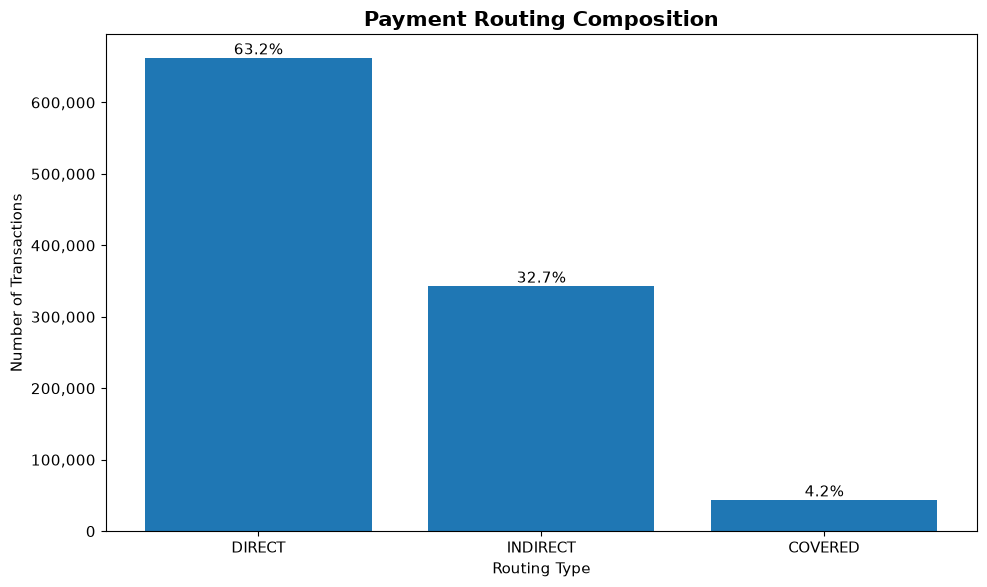

In [6]:
# ============================================================
# CELL 5 - ROUTING TYPE DISTRIBUTION
# Purpose:
# Visualize the baseline composition of payment routing types.
# ============================================================

plot_data = routing_table.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["ROUTING_TYPE"],
    plot_data["TRANSACTION_COUNT"]
)

ax.set_title(
    "Payment Routing Composition",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Routing Type")
ax.set_ylabel("Number of Transactions")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

for bar, percentage in zip(
    bars,
    plot_data["PERCENTAGE"]
):
    ax.annotate(
        f"{percentage:.1f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

export_chart("eda_routing_distribution.png")

plt.show()

6 — Routing Complexity Distribution

In [7]:
# ============================================================
# CELL 6 - ROUTING COMPLEXITY DISTRIBUTION
# Purpose:
# Understand participant and FX conversion distributions.
# ============================================================

participant_counter = Counter()
fx_counter = Counter()

for chunk in iter_cleaned_chunks([
    "PARTICIPANT_COUNT_NUM",
    "FX_COUNT_NUM"
]):

    participants = pd.to_numeric(
        chunk["PARTICIPANT_COUNT_NUM"],
        errors="coerce"
    )

    fx_steps = pd.to_numeric(
        chunk["FX_COUNT_NUM"],
        errors="coerce"
    )

    participant_counter.update(
        participants.value_counts(dropna=False).to_dict()
    )

    fx_counter.update(
        fx_steps.value_counts(dropna=False).to_dict()
    )


participant_table = create_frequency_table(
    participant_counter,
    "PARTICIPANT_COUNT"
)

fx_table = create_frequency_table(
    fx_counter,
    "FX_COUNT"
)

export_table(
    participant_table,
    "eda_participant_distribution.csv"
)

export_table(
    fx_table,
    "eda_fx_distribution.csv"
)

print("Participant Count Distribution:")
display(participant_table)

print("\nFX Conversion Count Distribution:")
display(fx_table)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_participant_distribution.csv
Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_fx_distribution.csv
Participant Count Distribution:


,PARTICIPANT_COUNT,TRANSACTION_COUNT,PERCENTAGE
0,2,662245,63.156665
1,3,243986,23.268340
2,4,89703,8.554753
3,5,33230,3.169063
4,6,12229,1.166249
5,7,4551,0.434018
6,8,1654,0.157738
7,9,601,0.057316
8,10,241,0.022984
9,11,90,0.008583



FX Conversion Count Distribution:


,FX_COUNT,TRANSACTION_COUNT,PERCENTAGE
0,1,617573,58.896407
1,2,211719,20.191117
2,0,113881,10.860549
3,3,70061,6.681544
4,4,23588,2.249529
5,5,7798,0.743676
6,6,2634,0.251198
7,7,869,0.082874
8,8,301,0.028706
9,9,101,0.009632


7 — Routing Type vs Participant Count

In [8]:
# ============================================================
# CELL 7 - ROUTING TYPE VS PARTICIPANT COUNT
# Purpose:
# Explore whether routing types differ in participant count.
# ============================================================

routing_participant_counter = Counter()

for chunk in iter_cleaned_chunks([
    "TRANSACTION_TYPE_CODE_STD",
    "PARTICIPANT_COUNT_NUM"
]):

    grouped = (
        chunk.groupby(
            [
                "TRANSACTION_TYPE_CODE_STD",
                "PARTICIPANT_COUNT_NUM"
            ],
            dropna=False
        )
        .size()
    )

    routing_participant_counter.update(
        grouped.to_dict()
    )


rows = [
    {
        "ROUTING_TYPE": routing,
        "PARTICIPANT_COUNT": participants,
        "TRANSACTION_COUNT": count
    }
    for (routing, participants), count
    in routing_participant_counter.items()
]

routing_participant_table = pd.DataFrame(rows)

routing_participant_table["WITHIN_ROUTING_PERCENT"] = (
    routing_participant_table["TRANSACTION_COUNT"]
    /
    routing_participant_table.groupby(
        "ROUTING_TYPE"
    )["TRANSACTION_COUNT"].transform("sum")
    * 100
)

routing_participant_table = (
    routing_participant_table.sort_values(
        ["ROUTING_TYPE", "PARTICIPANT_COUNT"]
    )
)

export_table(
    routing_participant_table,
    "eda_routing_vs_participants.csv"
)

display(routing_participant_table)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_routing_vs_participants.csv


,ROUTING_TYPE,PARTICIPANT_COUNT,TRANSACTION_COUNT,WITHIN_ROUTING_PERCENT
0,COVERED,3,27628,63.398963
1,COVERED,4,10091,23.156180
2,COVERED,5,3733,8.566249
3,COVERED,6,1340,3.074946
4,COVERED,7,482,1.106063
5,COVERED,8,186,0.426821
17,COVERED,9,75,0.172105
18,COVERED,10,29,0.066547
22,COVERED,11,10,0.022947
23,COVERED,12,3,0.006884


8 — Routing Type vs FX Conversion Count

In [9]:
# ============================================================
# CELL 8 - ROUTING TYPE VS FX COUNT
# Purpose:
# Investigate FX conversion patterns across routing categories.
# ============================================================

routing_fx_counter = Counter()

for chunk in iter_cleaned_chunks([
    "TRANSACTION_TYPE_CODE_STD",
    "FX_COUNT_NUM"
]):

    grouped = (
        chunk.groupby(
            [
                "TRANSACTION_TYPE_CODE_STD",
                "FX_COUNT_NUM"
            ],
            dropna=False
        )
        .size()
    )

    routing_fx_counter.update(grouped.to_dict())


routing_fx_table = pd.DataFrame([
    {
        "ROUTING_TYPE": routing,
        "FX_COUNT": fx,
        "TRANSACTION_COUNT": count
    }
    for (routing, fx), count
    in routing_fx_counter.items()
])

routing_fx_table["WITHIN_ROUTING_PERCENT"] = (
    routing_fx_table["TRANSACTION_COUNT"]
    /
    routing_fx_table.groupby(
        "ROUTING_TYPE"
    )["TRANSACTION_COUNT"].transform("sum")
    * 100
)

routing_fx_table = routing_fx_table.sort_values(
    ["ROUTING_TYPE", "FX_COUNT"]
)

export_table(
    routing_fx_table,
    "eda_routing_vs_fx.csv"
)

display(routing_fx_table)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_routing_vs_fx.csv


,ROUTING_TYPE,FX_COUNT,TRANSACTION_COUNT,WITHIN_ROUTING_PERCENT
0,COVERED,0,1537,3.527009
1,COVERED,1,6229,14.293910
2,COVERED,2,24276,55.707008
3,COVERED,3,7662,17.582266
4,COVERED,4,2625,6.023682
5,COVERED,5,803,1.842673
6,COVERED,6,287,0.658589
7,COVERED,7,109,0.250126
22,COVERED,8,37,0.084905
25,COVERED,9,9,0.020653


9 — Payment Duration Distribution

In [10]:
# ============================================================
# CELL 9 - PAYMENT DURATION DISTRIBUTION
# Purpose:
# Calculate exact payment duration statistics and percentiles.
# ============================================================

duration_parts = []

for chunk in iter_cleaned_chunks(["TOTAL_DURATION_NUM"]):

    values = pd.to_numeric(
        chunk["TOTAL_DURATION_NUM"],
        errors="coerce"
    )

    duration_parts.append(
        values.dropna().to_numpy(dtype=np.float64)
    )

all_durations = np.concatenate(duration_parts)

duration_stats = pd.DataFrame([
    {
        "METRIC": "Valid transactions",
        "VALUE": len(all_durations)
    },
    {
        "METRIC": "Mean duration (seconds)",
        "VALUE": np.mean(all_durations)
    },
    {
        "METRIC": "Median duration (seconds)",
        "VALUE": np.median(all_durations)
    },
    {
        "METRIC": "Minimum duration (seconds)",
        "VALUE": np.min(all_durations)
    },
    {
        "METRIC": "P90 duration (seconds)",
        "VALUE": np.percentile(all_durations, 90)
    },
    {
        "METRIC": "P95 duration (seconds)",
        "VALUE": np.percentile(all_durations, 95)
    },
    {
        "METRIC": "P99 duration (seconds)",
        "VALUE": np.percentile(all_durations, 99)
    },
    {
        "METRIC": "Maximum duration (seconds)",
        "VALUE": np.max(all_durations)
    }
])

export_table(
    duration_stats,
    "eda_duration_statistics.csv"
)

display(duration_stats)

print("Duration distribution analysis completed.")

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_duration_statistics.csv


,METRIC,VALUE
0,Valid transactions,1.048575e+06
1,Mean duration (seconds),7.724186e+02
2,Median duration (seconds),5.600000e+01
3,Minimum duration (seconds),2.000000e+00
4,P90 duration (seconds),2.548000e+03
5,P95 duration (seconds),3.404000e+03
6,P99 duration (seconds),5.288000e+03
7,Maximum duration (seconds),1.383100e+04


Duration distribution analysis completed.


10 — Visualize Payment Duration Distribution

Median Duration: 56.0
P90 Duration: 2548.0
P95 Duration: 3404.0
P99 Duration: 5288.0
Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_duration_short_range.png


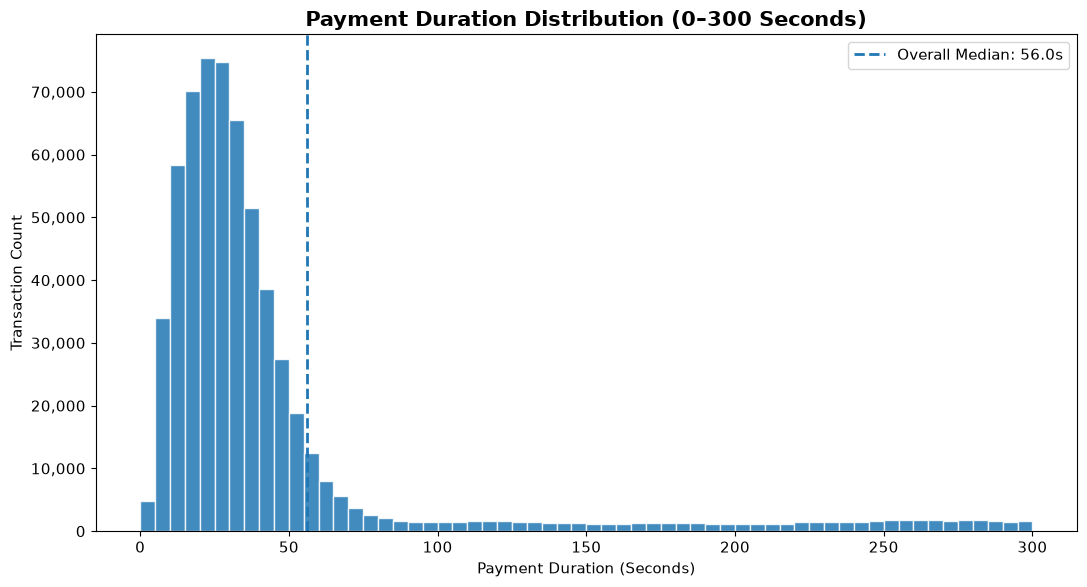

Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_duration_log_distribution.png


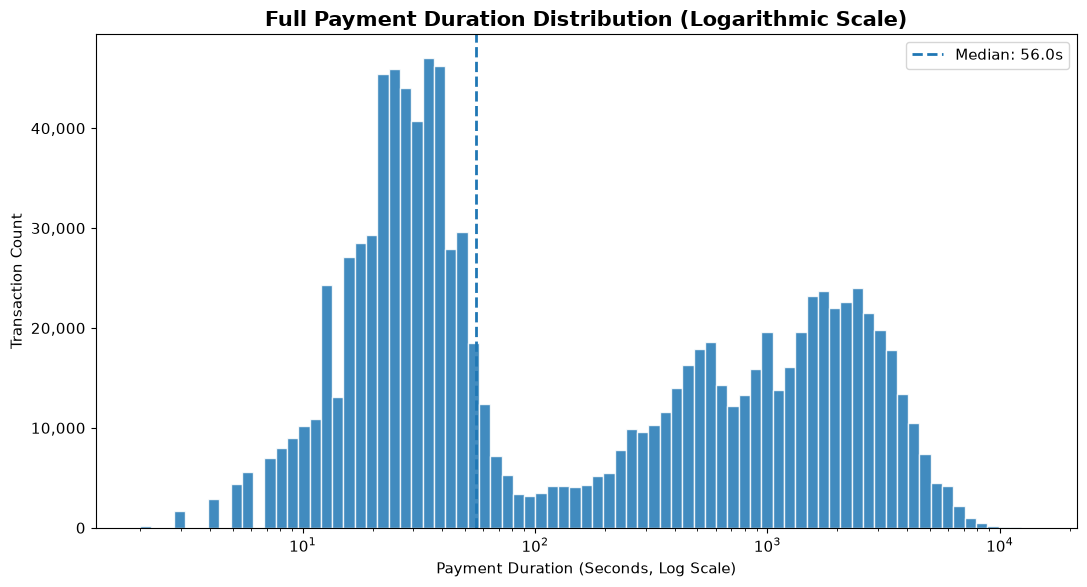


Duration visualizations completed.
No transaction records were removed or modified.


In [12]:
# ============================================================
# CELL 10 - IMPROVED PAYMENT DURATION VISUALIZATION
# Purpose:
# Examine short-duration concentration and the full
# payment duration distribution without modifying data.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# ------------------------------------------------------------
# 1. Calculate duration statistics
# ------------------------------------------------------------

median_duration = np.median(all_durations)
p90_duration = np.percentile(all_durations, 90)
p95_duration = np.percentile(all_durations, 95)
p99_duration = np.percentile(all_durations, 99)

print("Median Duration:", round(median_duration, 2))
print("P90 Duration:", round(p90_duration, 2))
print("P95 Duration:", round(p95_duration, 2))
print("P99 Duration:", round(p99_duration, 2))


# ------------------------------------------------------------
# 2. Zoom into short-duration transactions
# ------------------------------------------------------------

short_durations = all_durations[
    all_durations <= 300
]

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    short_durations,
    bins=np.arange(0, 305, 5),
    edgecolor="white",
    alpha=0.85
)

ax.axvline(
    median_duration,
    linestyle="--",
    linewidth=2,
    label=f"Overall Median: {median_duration:.1f}s"
)

ax.set_title(
    "Payment Duration Distribution (0–300 Seconds)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Payment Duration (Seconds)")
ax.set_ylabel("Transaction Count")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.legend()

plt.tight_layout()

export_chart("eda_duration_short_range.png")

plt.show()


# ------------------------------------------------------------
# 3. Visualize the full distribution using a log scale
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    all_durations,
    bins=np.logspace(
        np.log10(max(1, all_durations.min())),
        np.log10(all_durations.max()),
        80
    ),
    edgecolor="white",
    alpha=0.85
)

ax.set_xscale("log")

ax.axvline(
    median_duration,
    linestyle="--",
    linewidth=2,
    label=f"Median: {median_duration:.1f}s"
)

ax.set_title(
    "Full Payment Duration Distribution (Logarithmic Scale)",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Payment Duration (Seconds, Log Scale)")
ax.set_ylabel("Transaction Count")

ax.yaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}")
)

ax.legend()

plt.tight_layout()

export_chart("eda_duration_log_distribution.png")

plt.show()


print("\nDuration visualizations completed.")
print("No transaction records were removed or modified.")

11 — Median Duration by Routing Type

In [13]:
# ============================================================
# CELL 11 - DURATION BY ROUTING TYPE
# Purpose:
# Compare payment duration distributions across routing types.
# ============================================================

duration_by_route = defaultdict(list)

for chunk in iter_cleaned_chunks([
    "TRANSACTION_TYPE_CODE_STD",
    "TOTAL_DURATION_NUM"
]):

    chunk["TOTAL_DURATION_NUM"] = pd.to_numeric(
        chunk["TOTAL_DURATION_NUM"],
        errors="coerce"
    )

    for routing, group in chunk.groupby(
        "TRANSACTION_TYPE_CODE_STD",
        dropna=False
    ):

        key = (
            str(routing)
            if pd.notna(routing)
            else "MISSING"
        )

        values = (
            group["TOTAL_DURATION_NUM"]
            .dropna()
            .to_numpy(dtype=np.float64)
        )

        duration_by_route[key].append(values)


route_duration_rows = []

for routing, parts in duration_by_route.items():

    values = np.concatenate(parts)

    if len(values) == 0:
        continue

    route_duration_rows.append({
        "ROUTING_TYPE": routing,
        "VALID_DURATION_COUNT": len(values),
        "MEAN_DURATION": np.mean(values),
        "MEDIAN_DURATION": np.median(values),
        "P90_DURATION": np.percentile(values, 90),
        "P95_DURATION": np.percentile(values, 95),
        "MIN_DURATION": np.min(values),
        "MAX_DURATION": np.max(values)
    })


route_duration_table = pd.DataFrame(
    route_duration_rows
).sort_values("MEDIAN_DURATION")

export_table(
    route_duration_table,
    "eda_duration_by_routing.csv"
)

display(route_duration_table)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_duration_by_routing.csv


,ROUTING_TYPE,VALID_DURATION_COUNT,MEAN_DURATION,MEDIAN_DURATION,P90_DURATION,P95_DURATION,MIN_DURATION,MAX_DURATION
1,DIRECT,662245,663.384293,39.0,2344.0,3146.0,2.0,11263.0
2,INDIRECT,342752,964.706975,283.0,2927.0,3815.0,3.0,13831.0
0,COVERED,43578,916.991395,378.0,2801.0,3774.0,3.0,11876.0


12 — Visualize Median Duration by Routing Type

Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_median_duration_by_routing.png


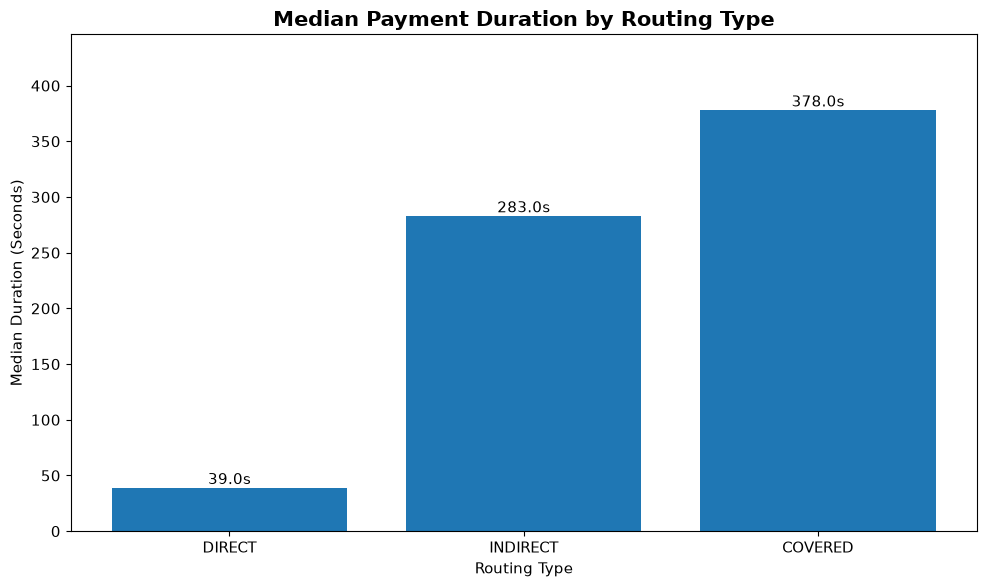

In [14]:
# ============================================================
# CELL 12 - VISUALIZE DURATION BY ROUTING TYPE
# Purpose:
# Compare median durations across routing categories.
# ============================================================

plot_data = route_duration_table.copy()

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    plot_data["ROUTING_TYPE"],
    plot_data["MEDIAN_DURATION"]
)

ax.set_title(
    "Median Payment Duration by Routing Type",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Routing Type")
ax.set_ylabel("Median Duration (Seconds)")

max_value = plot_data["MEDIAN_DURATION"].max()

ax.set_ylim(0, max_value * 1.18 if max_value > 0 else 1)

for bar in bars:

    height = bar.get_height()

    ax.annotate(
        f"{height:,.1f}s",
        (
            bar.get_x() + bar.get_width() / 2,
            height
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

export_chart("eda_median_duration_by_routing.png")

plt.show()

13 — Participant Count vs Payment Duration

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_duration_by_participants.csv


,PARTICIPANT_COUNT,TRANSACTION_COUNT,MEDIAN_DURATION,MEAN_DURATION,P90_DURATION
0,2,662245,39.0,663.384293,2344.0
1,3,243986,127.0,840.744194,2693.0
2,4,89703,420.0,1049.302487,3069.0
3,5,33230,583.0,1233.266536,3389.1
4,6,12229,807.0,1456.818055,3762.0
5,7,4551,1018.0,1636.198857,4078.0
6,8,1654,1252.5,1875.248489,4570.4
7,9,601,1324.0,1986.495840,4574.0
8,10,241,1554.0,1995.659751,4355.0
9,11,90,1593.0,2320.577778,5344.9


Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_duration_by_participants.png


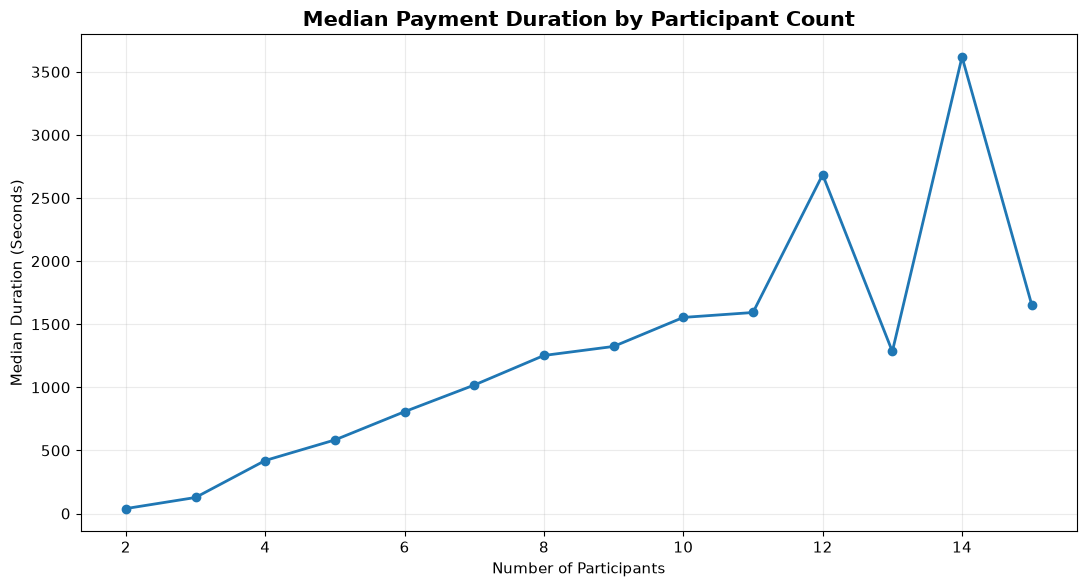

In [15]:
# ============================================================
# CELL 13 - PARTICIPANT COUNT VS DURATION
# Purpose:
# Investigate how duration varies with routing complexity.
# ============================================================

duration_by_participant = defaultdict(list)

for chunk in iter_cleaned_chunks([
    "PARTICIPANT_COUNT_NUM",
    "TOTAL_DURATION_NUM"
]):

    chunk["PARTICIPANT_COUNT_NUM"] = pd.to_numeric(
        chunk["PARTICIPANT_COUNT_NUM"],
        errors="coerce"
    )

    chunk["TOTAL_DURATION_NUM"] = pd.to_numeric(
        chunk["TOTAL_DURATION_NUM"],
        errors="coerce"
    )

    valid_chunk = chunk.dropna(
        subset=[
            "PARTICIPANT_COUNT_NUM",
            "TOTAL_DURATION_NUM"
        ]
    )

    for count, group in valid_chunk.groupby(
        "PARTICIPANT_COUNT_NUM"
    ):

        duration_by_participant[count].append(
            group["TOTAL_DURATION_NUM"].to_numpy(
                dtype=np.float64
            )
        )


participant_duration_rows = []

for count, parts in duration_by_participant.items():

    values = np.concatenate(parts)

    participant_duration_rows.append({
        "PARTICIPANT_COUNT": count,
        "TRANSACTION_COUNT": len(values),
        "MEDIAN_DURATION": np.median(values),
        "MEAN_DURATION": np.mean(values),
        "P90_DURATION": np.percentile(values, 90)
    })


participant_duration_table = pd.DataFrame(
    participant_duration_rows
).sort_values("PARTICIPANT_COUNT")

export_table(
    participant_duration_table,
    "eda_duration_by_participants.csv"
)

display(participant_duration_table)


# ------------------------------------------------------------
# Visualize the relationship
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    participant_duration_table["PARTICIPANT_COUNT"],
    participant_duration_table["MEDIAN_DURATION"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Median Payment Duration by Participant Count",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of Participants")
ax.set_ylabel("Median Duration (Seconds)")

ax.grid(alpha=0.25)

plt.tight_layout()

export_chart("eda_duration_by_participants.png")

plt.show()

14 — FX Conversion Count vs Payment Duration

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_duration_by_fx.csv


,FX_COUNT,TRANSACTION_COUNT,MEDIAN_DURATION,MEAN_DURATION,P90_DURATION
0,0,113881,48.0,717.408874,2423.0
1,1,617573,41.0,671.617198,2356.8
2,2,211719,183.0,881.879137,2787.0
3,3,70061,454.0,1097.055466,3157.0
4,4,23588,632.0,1300.343565,3519.0
5,5,7798,920.0,1546.410490,3883.3
6,6,2634,1052.0,1696.331435,4247.1
7,7,869,1371.0,1942.838895,4744.4
8,8,301,1492.0,2221.551495,5237.0
9,9,101,1532.0,2028.336634,4356.0


Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_duration_by_fx.png


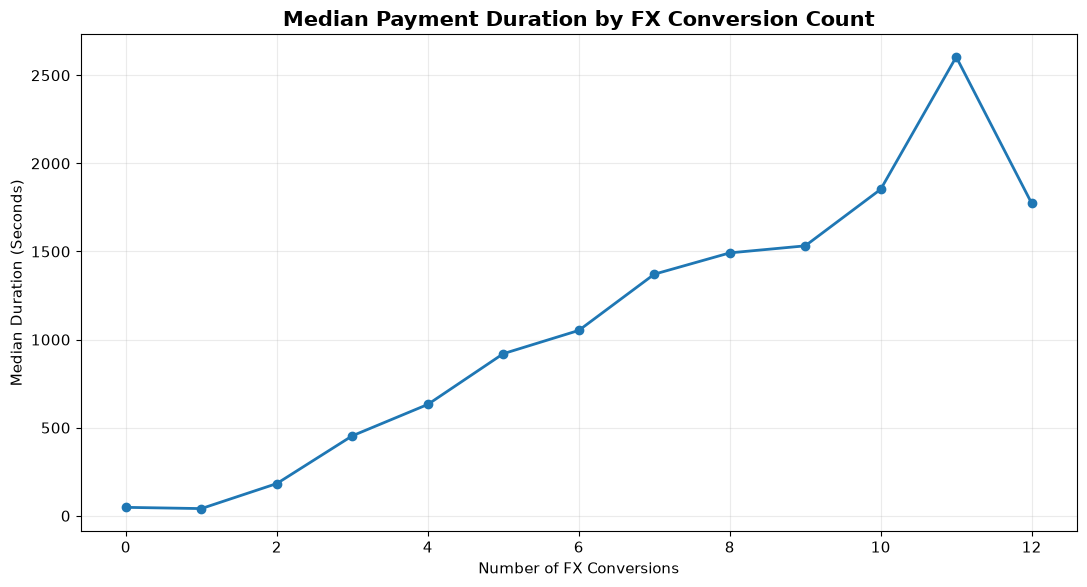

In [16]:
# ============================================================
# CELL 14 - FX CONVERSION VS DURATION
# Purpose:
# Explore payment duration patterns across FX conversion counts.
# ============================================================

duration_by_fx = defaultdict(list)

for chunk in iter_cleaned_chunks([
    "FX_COUNT_NUM",
    "TOTAL_DURATION_NUM"
]):

    chunk["FX_COUNT_NUM"] = pd.to_numeric(
        chunk["FX_COUNT_NUM"],
        errors="coerce"
    )

    chunk["TOTAL_DURATION_NUM"] = pd.to_numeric(
        chunk["TOTAL_DURATION_NUM"],
        errors="coerce"
    )

    valid_chunk = chunk.dropna(
        subset=[
            "FX_COUNT_NUM",
            "TOTAL_DURATION_NUM"
        ]
    )

    for fx_count, group in valid_chunk.groupby("FX_COUNT_NUM"):

        duration_by_fx[fx_count].append(
            group["TOTAL_DURATION_NUM"].to_numpy(
                dtype=np.float64
            )
        )


fx_duration_rows = []

for fx_count, parts in duration_by_fx.items():

    values = np.concatenate(parts)

    fx_duration_rows.append({
        "FX_COUNT": fx_count,
        "TRANSACTION_COUNT": len(values),
        "MEDIAN_DURATION": np.median(values),
        "MEAN_DURATION": np.mean(values),
        "P90_DURATION": np.percentile(values, 90)
    })


fx_duration_table = pd.DataFrame(
    fx_duration_rows
).sort_values("FX_COUNT")

export_table(
    fx_duration_table,
    "eda_duration_by_fx.csv"
)

display(fx_duration_table)


# ------------------------------------------------------------
# Visualize FX count and duration
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(
    fx_duration_table["FX_COUNT"],
    fx_duration_table["MEDIAN_DURATION"],
    marker="o",
    linewidth=2
)

ax.set_title(
    "Median Payment Duration by FX Conversion Count",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of FX Conversions")
ax.set_ylabel("Median Duration (Seconds)")

ax.grid(alpha=0.25)

plt.tight_layout()

export_chart("eda_duration_by_fx.png")

plt.show()

15 — Routing Path Continuity Analysis

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_routing_continuity.csv


,ROUTING_TYPE,HAS_PATH_GAP,TRANSACTION_COUNT,ROUTING_TOTAL,PERCENT_WITHIN_ROUTE
0,COVERED,N,38363,43578,88.032952
1,COVERED,Y,5215,43578,11.967048
2,DIRECT,N,629204,662245,95.010759
3,DIRECT,Y,33041,662245,4.989241
4,INDIRECT,N,300504,342752,87.673887
5,INDIRECT,Y,42248,342752,12.326113


Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_gap_rate_by_routing.csv


,ROUTING_TYPE,GAP_COUNT,ROUTING_TOTAL,GAP_RATE_PERCENT
1,COVERED,5215,43578,11.967048
3,DIRECT,33041,662245,4.989241
5,INDIRECT,42248,342752,12.326113


Chart exported: c:\Users\user\Documents\UMDAC_datathon\outputs\charts\eda_gap_rate_by_routing.png


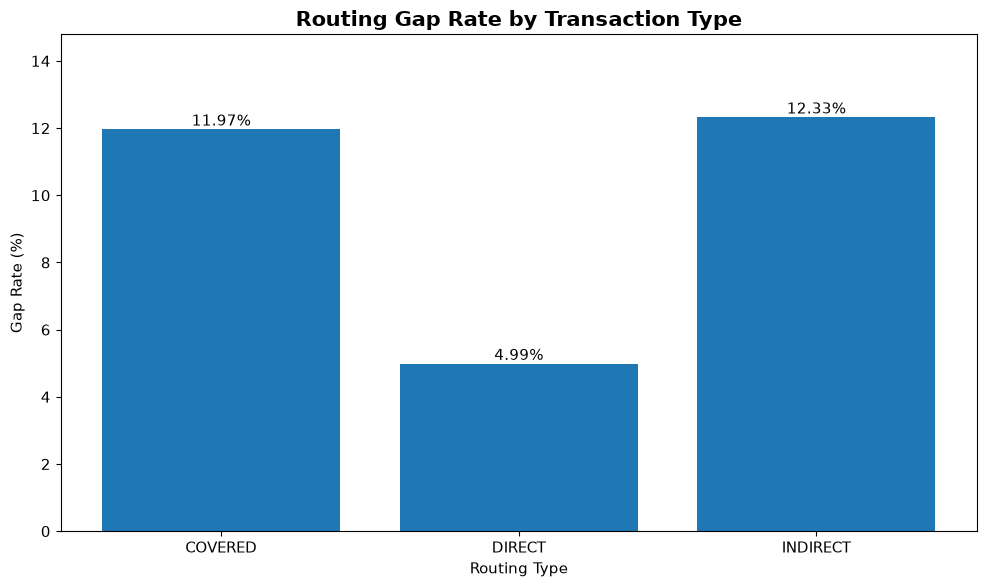

In [17]:
# ============================================================
# CELL 15 - ROUTING PATH CONTINUITY ANALYSIS
# Purpose:
# Compare routing gap rates across transaction types.
# ============================================================

continuity_counter = Counter()

for chunk in iter_cleaned_chunks([
    "TRANSACTION_TYPE_CODE_STD",
    "HAS_PATH_GAP"
]):

    grouped = (
        chunk.groupby(
            [
                "TRANSACTION_TYPE_CODE_STD",
                "HAS_PATH_GAP"
            ],
            dropna=False
        )
        .size()
    )

    continuity_counter.update(grouped.to_dict())


continuity_rows = [
    {
        "ROUTING_TYPE": routing,
        "HAS_PATH_GAP": gap,
        "TRANSACTION_COUNT": count
    }
    for (routing, gap), count
    in continuity_counter.items()
]

routing_continuity_table = pd.DataFrame(
    continuity_rows
)

routing_continuity_table["ROUTING_TOTAL"] = (
    routing_continuity_table.groupby(
        "ROUTING_TYPE"
    )["TRANSACTION_COUNT"].transform("sum")
)

routing_continuity_table["PERCENT_WITHIN_ROUTE"] = (
    routing_continuity_table["TRANSACTION_COUNT"]
    / routing_continuity_table["ROUTING_TOTAL"]
    * 100
)

export_table(
    routing_continuity_table,
    "eda_routing_continuity.csv"
)

display(routing_continuity_table)


# ------------------------------------------------------------
# Calculate routing gap rates
# ------------------------------------------------------------

gap_rate_table = (
    routing_continuity_table[
        routing_continuity_table["HAS_PATH_GAP"] == "Y"
    ][
        [
            "ROUTING_TYPE",
            "TRANSACTION_COUNT",
            "ROUTING_TOTAL",
            "PERCENT_WITHIN_ROUTE"
        ]
    ]
    .copy()
)

gap_rate_table = gap_rate_table.rename(columns={
    "TRANSACTION_COUNT": "GAP_COUNT",
    "PERCENT_WITHIN_ROUTE": "GAP_RATE_PERCENT"
})

export_table(
    gap_rate_table,
    "eda_gap_rate_by_routing.csv"
)

display(gap_rate_table)


# ------------------------------------------------------------
# Visualize gap rates
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    gap_rate_table["ROUTING_TYPE"],
    gap_rate_table["GAP_RATE_PERCENT"]
)

ax.set_title(
    "Routing Gap Rate by Transaction Type",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Routing Type")
ax.set_ylabel("Gap Rate (%)")

ax.set_ylim(
    0,
    max(1, gap_rate_table["GAP_RATE_PERCENT"].max() * 1.2)
)

for bar in bars:
    ax.annotate(
        f"{bar.get_height():.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

export_chart("eda_gap_rate_by_routing.png")

plt.show()

16 — Currency and Party Relationship Analysis

In [18]:
# ============================================================
# CELL 16 - CURRENCY AND PARTY RELATIONSHIP ANALYSIS
# Purpose:
# Compare currency preferences across party relationship types.
# ============================================================

currency_party_counter = Counter()

for chunk in iter_cleaned_chunks([
    "PARTY_PAIR",
    "CURRENCY_CODE_STD"
]):

    grouped = (
        chunk.groupby(
            ["PARTY_PAIR", "CURRENCY_CODE_STD"],
            dropna=False
        )
        .size()
    )

    currency_party_counter.update(grouped.to_dict())


currency_party_rows = [
    {
        "PARTY_PAIR": party,
        "CURRENCY": currency,
        "TRANSACTION_COUNT": count
    }
    for (party, currency), count
    in currency_party_counter.items()
]

currency_party_table = pd.DataFrame(
    currency_party_rows
)

currency_party_table["PARTY_TOTAL"] = (
    currency_party_table.groupby(
        "PARTY_PAIR"
    )["TRANSACTION_COUNT"].transform("sum")
)

currency_party_table["WITHIN_PARTY_PERCENT"] = (
    currency_party_table["TRANSACTION_COUNT"]
    / currency_party_table["PARTY_TOTAL"]
    * 100
)

currency_party_table = currency_party_table.sort_values(
    ["PARTY_PAIR", "TRANSACTION_COUNT"],
    ascending=[True, False]
)

export_table(
    currency_party_table,
    "eda_currency_by_party.csv"
)

print("Top currencies within each party relationship:")

display(
    currency_party_table.groupby(
        "PARTY_PAIR",
        group_keys=False
    ).head(10)
)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_currency_by_party.csv
Top currencies within each party relationship:


,PARTY_PAIR,CURRENCY,TRANSACTION_COUNT,PARTY_TOTAL,WITHIN_PARTY_PERCENT
37,B_B,EUR,76785,238634,32.176890
110,B_B,USD,42445,238634,17.786652
39,B_B,GBP,20843,238634,8.734296
25,B_B,CHF,15988,238634,6.699800
97,B_B,SGD,8917,238634,3.736685
27,B_B,CNY,8380,238634,3.511654
45,B_B,HKD,4916,238634,2.060058
55,B_B,JPY,4601,238634,1.928057
7,B_B,AUD,4032,238634,1.689617
24,B_B,CAD,2560,238634,1.072773


17 — Anomaly Distribution and Preliminary Screening

In [19]:
# ============================================================
# CELL 17 - ANOMALY DISTRIBUTION AND SCREENING
# Purpose:
# Examine labeled anomaly populations and sample sizes.
# ============================================================

anomaly_screening = anomaly_table.copy()

anomaly_screening["SAMPLE_SIZE_STATUS"] = np.where(
    anomaly_screening["TRANSACTION_COUNT"] >= 100,
    "SUFFICIENT_FOR_INITIAL_EXPLORATION",
    "SMALL_SAMPLE_REQUIRES_CAUTION"
)

anomaly_screening.loc[
    anomaly_screening["ANOMALY_TYPE"] == "UNLABELED",
    "SAMPLE_SIZE_STATUS"
] = "UNLABELED_POPULATION"

export_table(
    anomaly_screening,
    "eda_anomaly_screening.csv"
)

display(anomaly_screening)

print(
    "Note: Sample-size screening is descriptive only. "
    "It does not establish anomaly-generating rules."
)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_anomaly_screening.csv


,ANOMALY_TYPE,TRANSACTION_COUNT,PERCENTAGE,SAMPLE_SIZE_STATUS
0,UNLABELED,1047028,99.852466,UNLABELED_POPULATION
1,ROMANCE_SCAM,1065,0.101566,SUFFICIENT_FOR_INITIAL_EXPLORATION
2,FAT_FINGER_MISTAKE,199,0.018978,SUFFICIENT_FOR_INITIAL_EXPLORATION
3,CEO_SCAM,97,0.009251,SMALL_SAMPLE_REQUIRES_CAUTION
4,ACCOUNT_REPLACEMENT_SCAM,82,0.007820,SMALL_SAMPLE_REQUIRES_CAUTION
5,DUPLICATE_PAYMENT,72,0.006866,SMALL_SAMPLE_REQUIRES_CAUTION
6,CUSTOMER_RECALL,32,0.003052,SMALL_SAMPLE_REQUIRES_CAUTION


Note: Sample-size screening is descriptive only. It does not establish anomaly-generating rules.


18 — Token Pattern Overview

In [20]:
# ============================================================
# CELL 18 - TOKEN PATTERN OVERVIEW
# Purpose:
# Inspect basic structural properties of engineered token data.
# ============================================================

token_stats = {
    "RECORDS": 0,
    "ORDERING_BLANK": 0,
    "BENEFICIARY_BLANK": 0,
    "ORDERING_LENGTH_SUM": 0,
    "BENEFICIARY_LENGTH_SUM": 0
}

for chunk in iter_cleaned_chunks([
    "ORDERING_TOKENS",
    "BENEFICIARY_TOKENS"
]):

    ordering = (
        chunk["ORDERING_TOKENS"]
        .fillna("")
        .astype(str)
    )

    beneficiary = (
        chunk["BENEFICIARY_TOKENS"]
        .fillna("")
        .astype(str)
    )

    token_stats["RECORDS"] += len(chunk)

    token_stats["ORDERING_BLANK"] += int(
        ordering.str.strip().eq("").sum()
    )

    token_stats["BENEFICIARY_BLANK"] += int(
        beneficiary.str.strip().eq("").sum()
    )

    token_stats["ORDERING_LENGTH_SUM"] += int(
        ordering.str.len().sum()
    )

    token_stats["BENEFICIARY_LENGTH_SUM"] += int(
        beneficiary.str.len().sum()
    )


token_overview = pd.DataFrame([
    {
        "METRIC": "Ordering token blank records",
        "VALUE": token_stats["ORDERING_BLANK"]
    },
    {
        "METRIC": "Beneficiary token blank records",
        "VALUE": token_stats["BENEFICIARY_BLANK"]
    },
    {
        "METRIC": "Average ordering token string length",
        "VALUE": (
            token_stats["ORDERING_LENGTH_SUM"]
            / token_stats["RECORDS"]
        )
    },
    {
        "METRIC": "Average beneficiary token string length",
        "VALUE": (
            token_stats["BENEFICIARY_LENGTH_SUM"]
            / token_stats["RECORDS"]
        )
    }
])

export_table(
    token_overview,
    "eda_token_overview.csv"
)

display(token_overview)

Table exported: c:\Users\user\Documents\UMDAC_datathon\outputs\tables\eda_token_overview.csv


,METRIC,VALUE
0,Ordering token blank records,0.000000
1,Beneficiary token blank records,0.000000
2,Average ordering token string length,103.283036
3,Average beneficiary token string length,108.052042


19 — Generate Candidate Hypotheses Register

In [21]:
# ============================================================
# CELL 19 - GENERATE CANDIDATE HYPOTHESES
# Purpose:
# Prepare a structured research register for rule discovery.
# ============================================================

hypotheses = [
    {
        "ID": "H01",
        "FEATURE_GROUP": "Routing",
        "HYPOTHESIS": (
            "Routing type is associated with participant count."
        ),
        "TARGET_NOTEBOOK": "03_bank_routing.ipynb"
    },
    {
        "ID": "H02",
        "FEATURE_GROUP": "Routing",
        "HYPOTHESIS": (
            "FX conversion count is associated with routing type."
        ),
        "TARGET_NOTEBOOK": "03_bank_routing.ipynb"
    },
    {
        "ID": "H03",
        "FEATURE_GROUP": "Routing",
        "HYPOTHESIS": (
            "Certain currencies have different routing distributions."
        ),
        "TARGET_NOTEBOOK": "03_bank_routing.ipynb"
    },
    {
        "ID": "H04",
        "FEATURE_GROUP": "Routing",
        "HYPOTHESIS": (
            "Routing gaps are concentrated in specific routing groups."
        ),
        "TARGET_NOTEBOOK": "03_bank_routing.ipynb"
    },
    {
        "ID": "H05",
        "FEATURE_GROUP": "Routing",
        "HYPOTHESIS": (
            "Specific BIC pairs show recurring route preferences."
        ),
        "TARGET_NOTEBOOK": "03_bank_routing.ipynb"
    },
    {
        "ID": "H06",
        "FEATURE_GROUP": "Duration",
        "HYPOTHESIS": (
            "Payment duration differs across routing types."
        ),
        "TARGET_NOTEBOOK": "04_payment_duration.ipynb"
    },
    {
        "ID": "H07",
        "FEATURE_GROUP": "Duration",
        "HYPOTHESIS": (
            "Payment duration is associated with participant count."
        ),
        "TARGET_NOTEBOOK": "04_payment_duration.ipynb"
    },
    {
        "ID": "H08",
        "FEATURE_GROUP": "Duration",
        "HYPOTHESIS": (
            "FX conversion count is associated with payment duration."
        ),
        "TARGET_NOTEBOOK": "04_payment_duration.ipynb"
    },
    {
        "ID": "H09",
        "FEATURE_GROUP": "Duration",
        "HYPOTHESIS": (
            "Routing type remains associated with duration "
            "after accounting for participant count."
        ),
        "TARGET_NOTEBOOK": "04_payment_duration.ipynb"
    },
    {
        "ID": "H10",
        "FEATURE_GROUP": "Duration",
        "HYPOTHESIS": (
            "Routing path continuity is associated with duration."
        ),
        "TARGET_NOTEBOOK": "04_payment_duration.ipynb"
    },
    {
        "ID": "H11",
        "FEATURE_GROUP": "Currency",
        "HYPOTHESIS": (
            "Currency selection differs by party relationship."
        ),
        "TARGET_NOTEBOOK": "05_currency_party.ipynb"
    },
    {
        "ID": "H12",
        "FEATURE_GROUP": "Currency",
        "HYPOTHESIS": (
            "Currency and party relationship interact "
            "with routing preferences."
        ),
        "TARGET_NOTEBOOK": "05_currency_party.ipynb"
    },
    {
        "ID": "H13",
        "FEATURE_GROUP": "Anomaly",
        "HYPOTHESIS": (
            "Duplicate payment labels correspond to repeated "
            "sender-beneficiary-amount patterns."
        ),
        "TARGET_NOTEBOOK": "06_anomaly_analysis.ipynb"
    },
    {
        "ID": "H14",
        "FEATURE_GROUP": "Anomaly",
        "HYPOTHESIS": (
            "Anomaly categories show distinct payment "
            "amount or routing patterns."
        ),
        "TARGET_NOTEBOOK": "06_anomaly_analysis.ipynb"
    },
    {
        "ID": "H15",
        "FEATURE_GROUP": "Tokens",
        "HYPOTHESIS": (
            "Engineered token patterns are associated "
            "with party type or anomaly labels."
        ),
        "TARGET_NOTEBOOK": "07_tokens.ipynb"
    }
]

hypothesis_register = pd.DataFrame(hypotheses)

hypothesis_register["STATUS"] = "NOT_TESTED"
hypothesis_register["EVIDENCE"] = ""
hypothesis_register["CONFIDENCE"] = ""
hypothesis_register["BUSINESS_IMPLICATION"] = ""

hypothesis_path = (
    RULE_DIR / "candidate_hypotheses.csv"
)

hypothesis_register.to_csv(
    hypothesis_path,
    index=False,
    encoding="utf-8-sig"
)

print("Candidate hypotheses:", len(hypothesis_register))
print("Output:", hypothesis_path)

display(hypothesis_register)

Candidate hypotheses: 15
Output: c:\Users\user\Documents\UMDAC_datathon\outputs\rules\candidate_hypotheses.csv


,ID,FEATURE_GROUP,HYPOTHESIS,TARGET_NOTEBOOK,STATUS,EVIDENCE,CONFIDENCE,BUSINESS_IMPLICATION
0,H01,Routing,Routing type is associated with participant co...,03_bank_routing.ipynb,NOT_TESTED,,,
1,H02,Routing,FX conversion count is associated with routing...,03_bank_routing.ipynb,NOT_TESTED,,,
2,H03,Routing,Certain currencies have different routing dist...,03_bank_routing.ipynb,NOT_TESTED,,,
3,H04,Routing,Routing gaps are concentrated in specific rout...,03_bank_routing.ipynb,NOT_TESTED,,,
4,H05,Routing,Specific BIC pairs show recurring route prefer...,03_bank_routing.ipynb,NOT_TESTED,,,
5,H06,Duration,Payment duration differs across routing types.,04_payment_duration.ipynb,NOT_TESTED,,,
6,H07,Duration,Payment duration is associated with participan...,04_payment_duration.ipynb,NOT_TESTED,,,
7,H08,Duration,FX conversion count is associated with payment...,04_payment_duration.ipynb,NOT_TESTED,,,
8,H09,Duration,Routing type remains associated with duration ...,04_payment_duration.ipynb,NOT_TESTED,,,
9,H10,Duration,Routing path continuity is associated with dur...,04_payment_duration.ipynb,NOT_TESTED,,,


20 — Final EDA Validation & Output Summary

In [22]:
# ============================================================
# CELL 20 - FINAL EDA VALIDATION
# Purpose:
# Verify record coverage and summarize the analysis outputs.
# ============================================================

EXPECTED_RECORDS = 1_048_575

assert total_records == EXPECTED_RECORDS, (
    "EDA record count does not match the expected dataset."
)

assert routing_table["TRANSACTION_COUNT"].sum() == total_records

assert currency_table["TRANSACTION_COUNT"].sum() == total_records

assert party_table["TRANSACTION_COUNT"].sum() == total_records

assert continuity_table["TRANSACTION_COUNT"].sum() == total_records

assert anomaly_table["TRANSACTION_COUNT"].sum() == total_records


# ------------------------------------------------------------
# Validate duration population
# ------------------------------------------------------------

duration_valid_count = len(all_durations)

print("=" * 65)
print("SWIFT DATATHON - EDA VALIDATION")
print("=" * 65)

print("Expected transactions:", f"{EXPECTED_RECORDS:,}")
print("EDA transactions:", f"{total_records:,}")

print("Valid duration records:", f"{duration_valid_count:,}")
print("Routing categories:", len(routing_table))
print("Currency categories:", len(currency_table))
print("Party relationship groups:", len(party_table))
print("Candidate hypotheses:", len(hypothesis_register))

print("\nEvidence Tables:")
print(TABLE_DIR)

print("\nCharts:")
print(CHART_DIR)

print("\nHypothesis Register:")
print(hypothesis_path)

print("\nEDA completed successfully.")
print("No original transaction records were modified.")

SWIFT DATATHON - EDA VALIDATION
Expected transactions: 1,048,575
EDA transactions: 1,048,575
Valid duration records: 1,048,575
Routing categories: 3
Currency categories: 154
Party relationship groups: 4
Candidate hypotheses: 15

Evidence Tables:
c:\Users\user\Documents\UMDAC_datathon\outputs\tables

Charts:
c:\Users\user\Documents\UMDAC_datathon\outputs\charts

Hypothesis Register:
c:\Users\user\Documents\UMDAC_datathon\outputs\rules\candidate_hypotheses.csv

EDA completed successfully.
No original transaction records were modified.
